# Phase 15 — Extended Diagnostics: PR-AUC, Calibration, Threshold Sweep & Error-Overlap Analysis

**Notebook:** `14_extended_diagnostics.ipynb`

## Why this notebook exists

This is a lightweight, **retraining-free** diagnostics pass. It reads only already-saved
prediction files from Phases 13–14 — no model is retrained, no checkpoint is touched, no
fold is re-derived. It computes additional metrics needed for the paper:

- **PR-AUC** (more informative than ROC-AUC given the ~73% DM class prevalence in this pooled set)
- **Calibration quality** (reliability diagram + Brier score)
- **A full sensitivity/specificity threshold sweep**
- **A per-subject error OVERLAP analysis** between DualBranchGAT and the best TCI baseline
  (Section 6) — the most important part of this notebook, since it will determine whether a
  fusion model (Phase 16) is worth building.

## Files read (no retraining, no re-derivation)

1. `results/cv_pooled_predictions.csv` — 167 rows: `subject_id`, `group`, `true_label`,
   `mc_mean_prob` (DualBranchGAT's out-of-fold predicted probability), `pred_label_optimal`
   (DualBranchGAT's hard prediction at its own per-fold Youden's-J threshold), `fold`.
2. `results/baseline_pooled_predictions.csv` — 167 rows: `subject_id`, `group`, `true_label`,
   plus 4 probability columns, one per TCI baseline variant (no saved hard predictions).
3. `results/baseline_comparison.csv` — used only to identify which baseline variant is
   "best" (highest ROC-AUC), computed programmatically rather than hardcoded.

## Design note on thresholds — read carefully

DualBranchGAT already has a saved hard prediction (`pred_label_optimal`, from its own
per-fold Youden's-J-optimal threshold, computed back in Phase 13). The TCI baselines do
**not** have saved hard predictions or saved threshold values — only probabilities. For
every baseline-side hard classification needed in this notebook (the error-overlap analysis
in Section 6, and the reference sensitivity/specificity point in Section 5), a **plain 0.5
cutoff** is used on that baseline's probability column.

This is a known, deliberate asymmetry: DualBranchGAT uses its tuned per-fold threshold, the
baseline uses a flat 0.5. It is a reasonable simplification for a diagnostics notebook, not
a bug — but it is called out explicitly here rather than glossed over. Anywhere a hard
threshold is **not** needed (PR-AUC, the ROC-based sensitivity/specificity sweep itself,
Brier score, calibration), raw probabilities are used directly and this asymmetry never
comes into play.

## Section 0: Setup

Import libraries and define file paths. Everything used here (numpy, pandas, scikit-learn's
`metrics` module, matplotlib, json, pathlib) is already installed from prior phases — no new
dependencies.

In [1]:
import numpy as np
import pandas as pd
from sklearn.metrics import (
    average_precision_score,
    precision_recall_curve,
    roc_curve,
    brier_score_loss,
    confusion_matrix,
)
import matplotlib.pyplot as plt
import json
from pathlib import Path

RESULTS_DIR = Path("results")

CV_PREDICTIONS_PATH = RESULTS_DIR / "cv_pooled_predictions.csv"
BASELINE_PREDICTIONS_PATH = RESULTS_DIR / "baseline_pooled_predictions.csv"
BASELINE_COMPARISON_PATH = RESULTS_DIR / "baseline_comparison.csv"

SUMMARY_JSON_PATH = RESULTS_DIR / "extended_diagnostics_summary.json"
ERROR_OVERLAP_CSV_PATH = RESULTS_DIR / "error_overlap_subjects.csv"

RESULTS_DIR.mkdir(parents=True, exist_ok=True)

print("=== SECTION 0: Setup ===")
print(f"CV predictions path:       {CV_PREDICTIONS_PATH}")
print(f"Baseline predictions path: {BASELINE_PREDICTIONS_PATH}")
print(f"Baseline comparison path:  {BASELINE_COMPARISON_PATH}")
print(f"Summary JSON will be saved to: {SUMMARY_JSON_PATH}")
print(f"Error-overlap CSV will be saved to: {ERROR_OVERLAP_CSV_PATH}")

=== SECTION 0: Setup ===
CV predictions path:       results\cv_pooled_predictions.csv
Baseline predictions path: results\baseline_pooled_predictions.csv
Baseline comparison path:  results\baseline_comparison.csv
Summary JSON will be saved to: results\extended_diagnostics_summary.json
Error-overlap CSV will be saved to: results\error_overlap_subjects.csv


## Section 1: Load, Merge & Identify the Best Baseline

Load all three source files. Merge `cv_pooled_predictions.csv` and
`baseline_pooled_predictions.csv` on `subject_id`, and verify the merge produced exactly 167
rows with no duplicates and that `true_label`/`group` agree between the two files for every
subject before trusting anything downstream. Then identify `BEST_BASELINE_NAME` — the
baseline variant in `baseline_comparison.csv` with the highest ROC-AUC among the 4 baseline
variants (excluding the DualBranchGAT row) — computed programmatically rather than
hardcoded, even though it is expected to be `LR_worse_foot_tci` based on the last run.

In [2]:
print("=== SECTION 1: Load, Merge, and Identify Best Baseline ===")

cv_df = pd.read_csv(CV_PREDICTIONS_PATH)
baseline_df = pd.read_csv(BASELINE_PREDICTIONS_PATH)
comparison_df = pd.read_csv(BASELINE_COMPARISON_PATH)

print(f"cv_pooled_predictions.csv shape:       {cv_df.shape} (expected (167, 6))")
print(f"baseline_pooled_predictions.csv shape: {baseline_df.shape} (expected (167, 7))")
print(f"baseline_comparison.csv shape:         {comparison_df.shape} (expected (5, 5))")

merged_df = cv_df.merge(
    baseline_df,
    on="subject_id",
    how="inner",
    suffixes=("_gat", "_baseline"),
)

n_rows = len(merged_df)
n_unique_subjects = merged_df["subject_id"].nunique()
row_count_pass = (n_rows == 167) and (n_unique_subjects == 167) and (n_rows == n_unique_subjects)

print(f"\nMerged shape: {merged_df.shape}")
print(f"Row count == 167:            {n_rows == 167}")
print(f"Unique subject_id count == 167: {n_unique_subjects == 167}")
print(f"No duplicate merge rows:     {n_rows == n_unique_subjects}")
print(f"MERGE ROW COUNT CHECK: {'PASS' if row_count_pass else 'FAIL'}")

true_label_match = (merged_df["true_label_gat"] == merged_df["true_label_baseline"]).all()
group_match = (merged_df["group_gat"] == merged_df["group_baseline"]).all()

print(f"\ntrue_label agreement across both files: {'PASS' if true_label_match else 'FAIL'}")
print(f"group agreement across both files:      {'PASS' if group_match else 'FAIL'}")

if not (row_count_pass and true_label_match and group_match):
    raise AssertionError(
        "Merge integrity check failed -- see printed PASS/FAIL flags above. "
        "Stopping rather than proceeding on unreconciled data."
    )

# Standardize on a single true_label / group column now that they're confirmed identical
merged_df["true_label"] = merged_df["true_label_gat"]
merged_df["group"] = merged_df["group_gat"]
merged_df = merged_df.drop(
    columns=["true_label_gat", "true_label_baseline", "group_gat", "group_baseline"]
)

print("\n--- Identifying BEST_BASELINE_NAME from baseline_comparison.csv ---")
baseline_only_df = comparison_df[comparison_df["model"] != "DualBranchGAT"].copy()
print(
    baseline_only_df[["model", "roc_auc"]]
    .sort_values("roc_auc", ascending=False)
    .to_string(index=False)
)

BEST_BASELINE_NAME = baseline_only_df.loc[baseline_only_df["roc_auc"].idxmax(), "model"]
print(f"\nBEST_BASELINE_NAME (highest roc_auc among the 4 baseline variants): {BEST_BASELINE_NAME}")

=== SECTION 1: Load, Merge, and Identify Best Baseline ===
cv_pooled_predictions.csv shape:       (167, 6) (expected (167, 6))
baseline_pooled_predictions.csv shape: (167, 7) (expected (167, 7))
baseline_comparison.csv shape:         (5, 5) (expected (5, 5))

Merged shape: (167, 12)
Row count == 167:            True
Unique subject_id count == 167: True
No duplicate merge rows:     True
MERGE ROW COUNT CHECK: PASS

true_label agreement across both files: PASS
group agreement across both files:      PASS

--- Identifying BEST_BASELINE_NAME from baseline_comparison.csv ---
                  model  roc_auc
      LR_worse_foot_tci 0.858834
 AdaBoost_both_feet_tci 0.837523
       LR_both_feet_tci 0.828415
AdaBoost_worse_foot_tci 0.825137

BEST_BASELINE_NAME (highest roc_auc among the 4 baseline variants): LR_worse_foot_tci


## Section 2: Class Prevalence Context

Print the DM prevalence (positive rate) in the 167-subject pooled set. This number is the
PR-AUC "no-skill" baseline: a random classifier's *expected* PR-AUC equals the positive
rate, **not 0.5** the way ROC-AUC's no-skill reference is 0.5. Since this dataset's DM
prevalence is well above 50%, every PR-AUC value in Section 3 needs to be read against this
floor, not against 0.5.

In [3]:
print("=== SECTION 2: Class Prevalence Context ===")

n_subjects = len(merged_df)
n_dm = int((merged_df["true_label"] == 1).sum())
n_control = int((merged_df["true_label"] == 0).sum())
dm_prevalence = n_dm / n_subjects

print(f"Total subjects:            {n_subjects}")
print(f"DM (positive) subjects:    {n_dm}  ({dm_prevalence:.4f})")
print(f"Control (negative) subjects: {n_control}  ({1 - dm_prevalence:.4f})")

print(f"\nNO-SKILL PR-AUC BASELINE = {dm_prevalence:.4f}")
print(
    "Unlike ROC-AUC (where a random classifier scores ~0.5 regardless of class balance),\n"
    "a random classifier's expected PR-AUC equals the positive class's prevalence.\n"
    f"With DM prevalence at {dm_prevalence:.1%}, every PR-AUC value in Section 3 should be\n"
    f"read relative to this {dm_prevalence:.4f} floor, not against the 0.5 reference used\n"
    "for ROC-AUC."
)

NO_SKILL_PR_AUC = dm_prevalence

=== SECTION 2: Class Prevalence Context ===
Total subjects:            167
DM (positive) subjects:    122  (0.7305)
Control (negative) subjects: 45  (0.2695)

NO-SKILL PR-AUC BASELINE = 0.7305
Unlike ROC-AUC (where a random classifier scores ~0.5 regardless of class balance),
a random classifier's expected PR-AUC equals the positive class's prevalence.
With DM prevalence at 73.1%, every PR-AUC value in Section 3 should be
read relative to this 0.7305 floor, not against the 0.5 reference used
for ROC-AUC.


## Section 3: PR-AUC

Compute `average_precision_score` for DualBranchGAT's `mc_mean_prob` and for all 4 baseline
probability columns, all against `true_label`. Results are printed as a table sorted
descending, with the Section 2 no-skill baseline shown as a reference row. Precision-recall
curves for DualBranchGAT and `BEST_BASELINE_NAME` are plotted together, with a horizontal
dashed line at the no-skill baseline.

=== SECTION 3: PR-AUC (Precision-Recall Area Under Curve) ===
                               model   pr_auc
                       DualBranchGAT 0.953690
                   LR_worse_foot_tci 0.950377
              AdaBoost_both_feet_tci 0.942527
                    LR_both_feet_tci 0.938608
             AdaBoost_worse_foot_tci 0.921801
(no-skill baseline, = DM prevalence) 0.730539


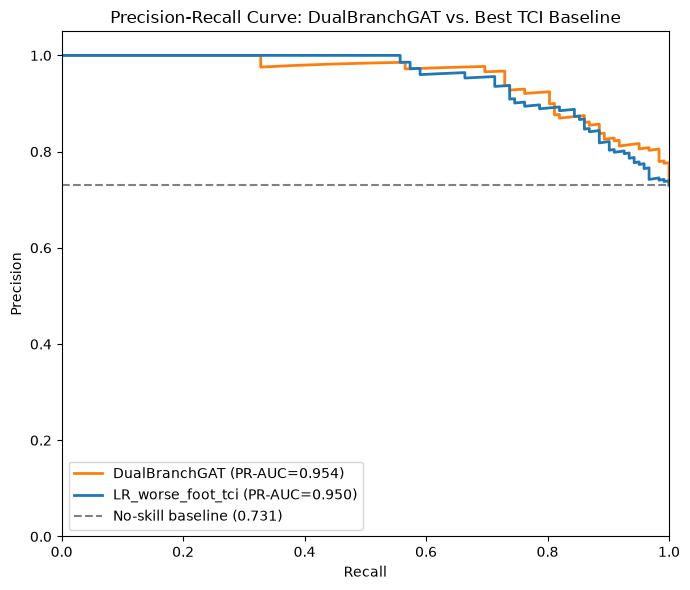

In [4]:
print("=== SECTION 3: PR-AUC (Precision-Recall Area Under Curve) ===")

y_true = merged_df["true_label"].values

prob_columns = {
    "DualBranchGAT": "mc_mean_prob",
    "LR_worse_foot_tci": "LR_worse_foot_tci",
    "LR_both_feet_tci": "LR_both_feet_tci",
    "AdaBoost_worse_foot_tci": "AdaBoost_worse_foot_tci",
    "AdaBoost_both_feet_tci": "AdaBoost_both_feet_tci",
}

pr_auc_results = {}
for name, col in prob_columns.items():
    pr_auc_results[name] = float(average_precision_score(y_true, merged_df[col].values))

pr_auc_df = (
    pd.DataFrame({"model": list(pr_auc_results.keys()), "pr_auc": list(pr_auc_results.values())})
    .sort_values("pr_auc", ascending=False)
    .reset_index(drop=True)
)

no_skill_row = pd.DataFrame(
    {"model": ["(no-skill baseline, = DM prevalence)"], "pr_auc": [NO_SKILL_PR_AUC]}
)
pr_auc_display_df = pd.concat([pr_auc_df, no_skill_row], ignore_index=True)

print(pr_auc_display_df.to_string(index=False))

fig, ax = plt.subplots(figsize=(7, 6))

precision_gat, recall_gat, _ = precision_recall_curve(y_true, merged_df["mc_mean_prob"].values)
ax.plot(
    recall_gat,
    precision_gat,
    label=f"DualBranchGAT (PR-AUC={pr_auc_results['DualBranchGAT']:.3f})",
    color="#ff7f0e",
    linewidth=2,
)

precision_base, recall_base, _ = precision_recall_curve(
    y_true, merged_df[BEST_BASELINE_NAME].values
)
ax.plot(
    recall_base,
    precision_base,
    label=f"{BEST_BASELINE_NAME} (PR-AUC={pr_auc_results[BEST_BASELINE_NAME]:.3f})",
    color="#1f77b4",
    linewidth=2,
)

ax.axhline(
    NO_SKILL_PR_AUC,
    linestyle="--",
    color="gray",
    label=f"No-skill baseline ({NO_SKILL_PR_AUC:.3f})",
)
ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.set_title("Precision-Recall Curve: DualBranchGAT vs. Best TCI Baseline")
ax.legend(loc="lower left")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1.05)
plt.tight_layout()
plt.show()

## Section 4: Calibration (Reliability Diagram + Brier Score)

For DualBranchGAT and `BEST_BASELINE_NAME`: build an 8-bin reliability diagram (mean
predicted probability vs. observed fraction positive per bin, against a diagonal "perfectly
calibrated" reference line), and compute the Brier score (mean squared error between
predicted probability and `true_label`, lower is better). Both models' reliability curves
are plotted on one figure, and both Brier scores are printed in a small table.

=== SECTION 4: Calibration (Reliability Diagram + Brier Score) ===
Brier scores (lower is better):
            model  brier_score
    DualBranchGAT     0.127190
LR_worse_foot_tci     0.158872


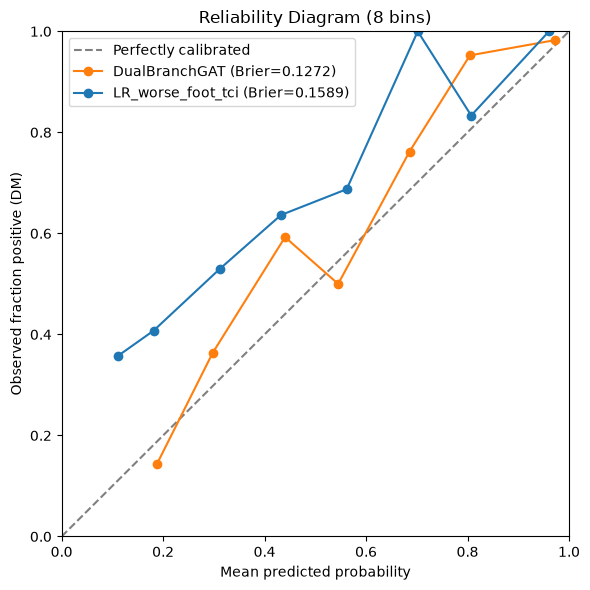

In [5]:
print("=== SECTION 4: Calibration (Reliability Diagram + Brier Score) ===")

def reliability_curve(y_true_arr, y_prob_arr, n_bins=8):
    # Returns (mean_predicted, frac_positive, bin_counts), one entry per bin.
    bin_edges = np.linspace(0.0, 1.0, n_bins + 1)
    bin_ids = np.digitize(y_prob_arr, bin_edges[1:-1], right=True)
    mean_predicted = np.full(n_bins, np.nan)
    frac_positive = np.full(n_bins, np.nan)
    bin_counts = np.zeros(n_bins, dtype=int)
    for b in range(n_bins):
        mask = bin_ids == b
        bin_counts[b] = mask.sum()
        if mask.sum() > 0:
            mean_predicted[b] = y_prob_arr[mask].mean()
            frac_positive[b] = y_true_arr[mask].mean()
    return mean_predicted, frac_positive, bin_counts

brier_scores = {}
for name in ["DualBranchGAT", BEST_BASELINE_NAME]:
    col = "mc_mean_prob" if name == "DualBranchGAT" else name
    brier_scores[name] = float(brier_score_loss(y_true, merged_df[col].values))

brier_df = pd.DataFrame(
    {"model": list(brier_scores.keys()), "brier_score": list(brier_scores.values())}
)
print("Brier scores (lower is better):")
print(brier_df.to_string(index=False))

fig, ax = plt.subplots(figsize=(6, 6))
ax.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Perfectly calibrated")

colors = {"DualBranchGAT": "#ff7f0e", BEST_BASELINE_NAME: "#1f77b4"}
for name in ["DualBranchGAT", BEST_BASELINE_NAME]:
    col = "mc_mean_prob" if name == "DualBranchGAT" else name
    mean_pred, frac_pos, counts = reliability_curve(y_true, merged_df[col].values, n_bins=8)
    valid = ~np.isnan(mean_pred)
    ax.plot(
        mean_pred[valid],
        frac_pos[valid],
        marker="o",
        label=f"{name} (Brier={brier_scores[name]:.4f})",
        color=colors[name],
    )

ax.set_xlabel("Mean predicted probability")
ax.set_ylabel("Observed fraction positive (DM)")
ax.set_title("Reliability Diagram (8 bins)")
ax.legend(loc="upper left")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
plt.tight_layout()
plt.show()

## Section 5: Sensitivity / Specificity Threshold Sweep

For DualBranchGAT's `mc_mean_prob` and `BEST_BASELINE_NAME`'s probability column, sweep the
classification threshold from 0.0 to 1.0 in steps of 0.05, computing sensitivity (recall on
`true_label==1`, i.e. DM) and specificity (recall on `true_label==0`, i.e. Control) at each
threshold. Both curves are plotted for both models (4 lines total, clearly labeled and
colored).

As a specific reference point, the sensitivity/specificity DualBranchGAT actually achieves
AT its saved `pred_label_optimal` predictions is also printed (computed directly via
`confusion_matrix` on the saved hard predictions, not re-derived from the sweep above),
alongside `BEST_BASELINE_NAME`'s sensitivity/specificity at the flat 0.5 cutoff (per the
design note in the notebook introduction).

=== SECTION 5: Sensitivity / Specificity Threshold Sweep ===


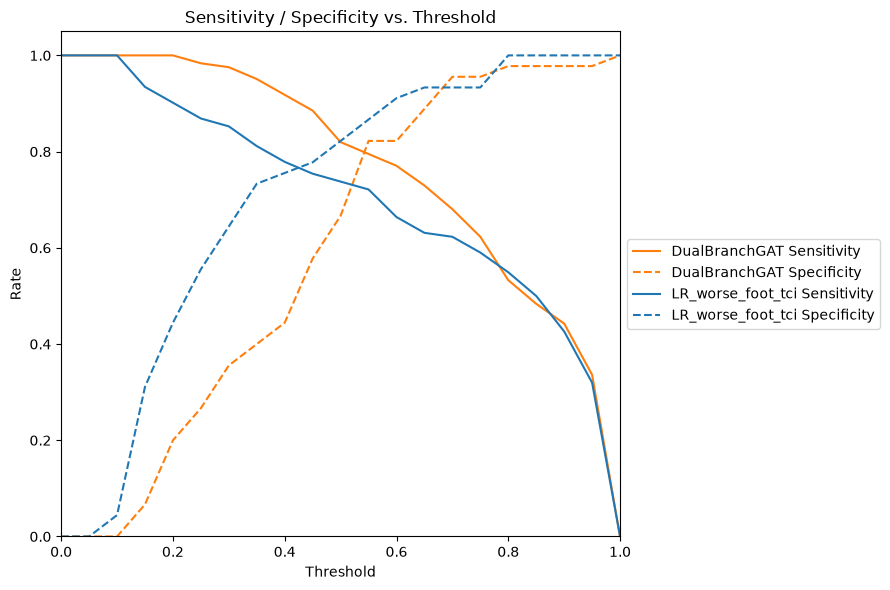


--- Reference points (actual saved hard predictions, not re-derived from the sweep) ---
DualBranchGAT AT its saved pred_label_optimal: sensitivity=0.8689, specificity=0.6444
LR_worse_foot_tci AT flat 0.5 cutoff: sensitivity=0.7377, specificity=0.8222


In [6]:
print("=== SECTION 5: Sensitivity / Specificity Threshold Sweep ===")

def sens_spec_sweep(y_true_arr, y_prob_arr, thresholds_arr):
    sens_list, spec_list = [], []
    for t in thresholds_arr:
        pred = (y_prob_arr >= t).astype(int)
        tn, fp, fn, tp = confusion_matrix(y_true_arr, pred, labels=[0, 1]).ravel()
        sensitivity = tp / (tp + fn) if (tp + fn) > 0 else np.nan
        specificity = tn / (tn + fp) if (tn + fp) > 0 else np.nan
        sens_list.append(sensitivity)
        spec_list.append(specificity)
    return np.array(sens_list), np.array(spec_list)

thresholds = np.round(np.arange(0.0, 1.0001, 0.05), 2)

gat_sens, gat_spec = sens_spec_sweep(y_true, merged_df["mc_mean_prob"].values, thresholds)
base_sens, base_spec = sens_spec_sweep(y_true, merged_df[BEST_BASELINE_NAME].values, thresholds)

fig, ax = plt.subplots(figsize=(9, 6))
ax.plot(thresholds, gat_sens, label="DualBranchGAT Sensitivity", color="#ff7f0e", linestyle="-")
ax.plot(thresholds, gat_spec, label="DualBranchGAT Specificity", color="#ff7f0e", linestyle="--")
ax.plot(
    thresholds,
    base_sens,
    label=f"{BEST_BASELINE_NAME} Sensitivity",
    color="#1f77b4",
    linestyle="-",
)
ax.plot(
    thresholds,
    base_spec,
    label=f"{BEST_BASELINE_NAME} Specificity",
    color="#1f77b4",
    linestyle="--",
)
ax.set_xlabel("Threshold")
ax.set_ylabel("Rate")
ax.set_title("Sensitivity / Specificity vs. Threshold")
ax.legend(loc="center left", bbox_to_anchor=(1.0, 0.5))
ax.set_xlim(0, 1)
ax.set_ylim(0, 1.05)
plt.tight_layout()
plt.show()

print("\n--- Reference points (actual saved hard predictions, not re-derived from the sweep) ---")

tn, fp, fn, tp = confusion_matrix(
    merged_df["true_label"], merged_df["pred_label_optimal"], labels=[0, 1]
).ravel()
gat_sens_at_optimal = tp / (tp + fn) if (tp + fn) > 0 else np.nan
gat_spec_at_optimal = tn / (tn + fp) if (tn + fp) > 0 else np.nan
print(
    f"DualBranchGAT AT its saved pred_label_optimal: "
    f"sensitivity={gat_sens_at_optimal:.4f}, specificity={gat_spec_at_optimal:.4f}"
)

baseline_pred_at_05 = (merged_df[BEST_BASELINE_NAME] >= 0.5).astype(int)
tn_b, fp_b, fn_b, tp_b = confusion_matrix(
    merged_df["true_label"], baseline_pred_at_05, labels=[0, 1]
).ravel()
base_sens_at_05 = tp_b / (tp_b + fn_b) if (tp_b + fn_b) > 0 else np.nan
base_spec_at_05 = tn_b / (tn_b + fp_b) if (tn_b + fp_b) > 0 else np.nan
print(
    f"{BEST_BASELINE_NAME} AT flat 0.5 cutoff: "
    f"sensitivity={base_sens_at_05:.4f}, specificity={base_spec_at_05:.4f}"
)

## Section 6: Error Overlap / Complementarity Analysis

**The most important section in this notebook.** Using DualBranchGAT's `pred_label_optimal`
and `BEST_BASELINE_NAME`'s probability thresholded at 0.5, every one of the 167 subjects is
classified into exactly one of four groups:

- **(a) BOTH_CORRECT** — both models got it right
- **(b) GAT_ONLY_CORRECT** — DualBranchGAT right, baseline wrong
- **(c) BASELINE_ONLY_CORRECT** — baseline right, DualBranchGAT wrong
- **(d) BOTH_WRONG** — both models got it wrong

Counts and percentages are printed for each group, along with the full `subject_id` list for
groups (b), (c), and (d) — these are the interesting cases for later qualitative review and
for informing Phase 16's fusion model. A cross-tab breaking down group membership by true
Group (Control/DM) is also printed, to check whether any group (e.g. BASELINE_ONLY_CORRECT)
is disproportionately one class.

In [7]:
print("=== SECTION 6: Error Overlap / Complementarity Analysis ===")

merged_df["gat_pred"] = merged_df["pred_label_optimal"]
merged_df["baseline_pred"] = (merged_df[BEST_BASELINE_NAME] >= 0.5).astype(int)

merged_df["gat_correct"] = merged_df["gat_pred"] == merged_df["true_label"]
merged_df["baseline_correct"] = merged_df["baseline_pred"] == merged_df["true_label"]

def overlap_group(row):
    if row["gat_correct"] and row["baseline_correct"]:
        return "BOTH_CORRECT"
    elif row["gat_correct"] and not row["baseline_correct"]:
        return "GAT_ONLY_CORRECT"
    elif not row["gat_correct"] and row["baseline_correct"]:
        return "BASELINE_ONLY_CORRECT"
    else:
        return "BOTH_WRONG"

merged_df["overlap_group"] = merged_df.apply(overlap_group, axis=1)

overlap_order = ["BOTH_CORRECT", "GAT_ONLY_CORRECT", "BASELINE_ONLY_CORRECT", "BOTH_WRONG"]
group_counts = merged_df["overlap_group"].value_counts()
group_pct = (group_counts / len(merged_df) * 100).round(2)

print("Error overlap group counts:")
for g in overlap_order:
    count = int(group_counts.get(g, 0))
    pct = float(group_pct.get(g, 0.0))
    print(f"  {g}: {count} ({pct}%)")

print("\n--- Subject IDs for interesting groups (b), (c), (d) ---")
for g in ["GAT_ONLY_CORRECT", "BASELINE_ONLY_CORRECT", "BOTH_WRONG"]:
    subjects = merged_df.loc[merged_df["overlap_group"] == g, "subject_id"].tolist()
    print(f"\n{g} (n={len(subjects)}):")
    print(subjects)

print("\n--- Cross-tab: overlap_group x true Group (Control/DM) ---")
cross_tab = pd.crosstab(merged_df["overlap_group"], merged_df["group"])
cross_tab = cross_tab.reindex(overlap_order)
print(cross_tab.to_string())

cross_tab_pct = (
    pd.crosstab(merged_df["overlap_group"], merged_df["group"], normalize="index").round(4) * 100
)
cross_tab_pct = cross_tab_pct.reindex(overlap_order)
print("\nCross-tab as row percentages (within each overlap group, % Control vs. % DM):")
print(cross_tab_pct.to_string())

=== SECTION 6: Error Overlap / Complementarity Analysis ===
Error overlap group counts:
  BOTH_CORRECT: 116 (69.46%)
  GAT_ONLY_CORRECT: 19 (11.38%)
  BASELINE_ONLY_CORRECT: 11 (6.59%)
  BOTH_WRONG: 21 (12.57%)

--- Subject IDs for interesting groups (b), (c), (d) ---

GAT_ONLY_CORRECT (n=19):
['DM052', 'DM066', 'DM117', 'DM122', 'DM037', 'DM056', 'DM058', 'DM062', 'DM101', 'DM105', 'DM003', 'CG044', 'DM044', 'DM049', 'DM094', 'DM030', 'DM090', 'DM096', 'DM111']

BASELINE_ONLY_CORRECT (n=11):
['CG024', 'CG042', 'CG008', 'CG016', 'CG018', 'CG019', 'CG020', 'CG043', 'DM065', 'DM104', 'CG017']

BOTH_WRONG (n=21):
['DM013', 'CG015', 'CG037', 'CG003', 'CG014', 'CG039', 'DM028', 'DM061', 'DM071', 'DM033', 'DM081', 'DM095', 'DM112', 'DM113', 'CG040', 'CG045', 'DM002', 'DM005', 'DM053', 'DM079', 'DM110']

--- Cross-tab: overlap_group x true Group (Control/DM) ---
group                  Control  DM
overlap_group                     
BOTH_CORRECT                28  88
GAT_ONLY_CORRECT           

## Section 7: Interpretation (fill in after reviewing the Section 6 output above)

Based on the printed `GAT_ONLY_CORRECT` and `BASELINE_ONLY_CORRECT` counts/percentages, and
the cross-tab, above:

- Are **both** groups non-trivial in size — suggesting DualBranchGAT and
  `BEST_BASELINE_NAME` make meaningfully different mistakes, which would make a
  fusion/stacking model (Phase 16) worth trying?
- Or is one model's correct set nearly a **subset** of the other's — suggesting a fusion
  model would add little?
- State this plainly and directly, referencing the actual counts/percentages from Section 6
  — don't round up or hedge past what the numbers show.
- Note what the cross-tab says: is `BASELINE_ONLY_CORRECT` or `GAT_ONLY_CORRECT`
  disproportionately Control or DM?

**[FILL IN based on the printed Section 6 output above once this notebook has been run
against the real prediction files.]**

## Section 8: Save Results

Save `results/extended_diagnostics_summary.json` (PR-AUC values, Brier scores, the no-skill
baseline, and the Section 6 error-overlap group counts/cross-tab) and
`results/error_overlap_subjects.csv` (167 rows: `subject_id`, `group`, `true_label`,
`gat_correct`, `baseline_correct`, `overlap_group`).

In [8]:
print("=== SECTION 8: Save Results ===")

summary_dict = {
    "pr_auc": pr_auc_results,
    "no_skill_pr_auc_baseline": NO_SKILL_PR_AUC,
    "dm_prevalence": dm_prevalence,
    "brier_scores": brier_scores,
    "best_baseline_name": BEST_BASELINE_NAME,
    "error_overlap_group_counts": {g: int(group_counts.get(g, 0)) for g in overlap_order},
    "error_overlap_group_percent": {g: float(group_pct.get(g, 0.0)) for g in overlap_order},
    "error_overlap_crosstab_counts": {
        str(k): {str(kk): int(vv) for kk, vv in v.items()} for k, v in cross_tab.to_dict().items()
    },
    "error_overlap_crosstab_row_percent": {
        str(k): {str(kk): float(vv) for kk, vv in v.items()}
        for k, v in cross_tab_pct.to_dict().items()
    },
    "sensitivity_specificity_reference_points": {
        "DualBranchGAT_at_pred_label_optimal": {
            "sensitivity": float(gat_sens_at_optimal),
            "specificity": float(gat_spec_at_optimal),
        },
        f"{BEST_BASELINE_NAME}_at_0.5_cutoff": {
            "sensitivity": float(base_sens_at_05),
            "specificity": float(base_spec_at_05),
        },
    },
}

with open(SUMMARY_JSON_PATH, "w") as f:
    json.dump(summary_dict, f, indent=2)
print(f"Saved: {SUMMARY_JSON_PATH}")

error_overlap_export_df = merged_df[
    ["subject_id", "group", "true_label", "gat_correct", "baseline_correct", "overlap_group"]
].copy()
error_overlap_export_df.to_csv(ERROR_OVERLAP_CSV_PATH, index=False)
print(
    f"Saved: {ERROR_OVERLAP_CSV_PATH} "
    f"(shape {error_overlap_export_df.shape}, expected (167, 6))"
)

=== SECTION 8: Save Results ===
Saved: results\extended_diagnostics_summary.json
Saved: results\error_overlap_subjects.csv (shape (167, 6), expected (167, 6))


## Section 9: Final Summary

Print PR-AUC and Brier score for DualBranchGAT vs. `BEST_BASELINE_NAME` side by side, repeat
the Section 6 group counts, and list any issues found across the notebook (or state "0
issues found"). Whether this notebook's evidence supports moving forward with a fusion model
in Phase 16 is stated in the Section 7 interpretation cell above, based on the actual printed
numbers.

In [9]:
print("=== SECTION 9: Final Summary ===")

print("--- PR-AUC vs. Brier score, DualBranchGAT vs. best baseline ---")
print(f"{'model':<25}{'PR-AUC':>10}{'Brier':>10}")
for name in ["DualBranchGAT", BEST_BASELINE_NAME]:
    print(f"{name:<25}{pr_auc_results[name]:>10.4f}{brier_scores[name]:>10.4f}")

print(f"\n(no-skill PR-AUC reference = {NO_SKILL_PR_AUC:.4f}, the DM prevalence)")

print("\n--- Error overlap group counts (repeated from Section 6) ---")
for g in overlap_order:
    count = int(group_counts.get(g, 0))
    pct = float(group_pct.get(g, 0.0))
    print(f"  {g}: {count} ({pct}%)")

issues_found = []
if not row_count_pass:
    issues_found.append("Merge did not produce exactly 167 unique-subject rows.")
if not true_label_match:
    issues_found.append(
        "true_label disagreed between cv_pooled_predictions.csv and "
        "baseline_pooled_predictions.csv for at least one subject."
    )
if not group_match:
    issues_found.append(
        "group disagreed between cv_pooled_predictions.csv and "
        "baseline_pooled_predictions.csv for at least one subject."
    )

print("\n--- Issues found ---")
if issues_found:
    for issue in issues_found:
        print(f"  - {issue}")
else:
    print("  0 issues found")

print(
    "\nSee the Section 7 interpretation markdown cell above for whether this notebook's "
    "evidence supports moving forward with a fusion model in Phase 16."
)

=== SECTION 9: Final Summary ===
--- PR-AUC vs. Brier score, DualBranchGAT vs. best baseline ---
model                        PR-AUC     Brier
DualBranchGAT                0.9537    0.1272
LR_worse_foot_tci            0.9504    0.1589

(no-skill PR-AUC reference = 0.7305, the DM prevalence)

--- Error overlap group counts (repeated from Section 6) ---
  BOTH_CORRECT: 116 (69.46%)
  GAT_ONLY_CORRECT: 19 (11.38%)
  BASELINE_ONLY_CORRECT: 11 (6.59%)
  BOTH_WRONG: 21 (12.57%)

--- Issues found ---
  0 issues found

See the Section 7 interpretation markdown cell above for whether this notebook's evidence supports moving forward with a fusion model in Phase 16.
